# Hull-White V4 —— 信用模型市场基准评估

**相对 V3 的改动**：V3 把评估任务定义为“预测离散 default_label”，但 `config.py:69-93` 把 20 家违约公司的 distress_date 硬编码为 2023-12-31，导致所有正例集中在单一年份（cell `accd66df` / `0ee19e4a` 已证明经典 walk-forward训练集正例数=0 而失败）。V3 报告的 pooled AUC=0.9754（Stage A）和 0.9936（Stage B2）本质是 **within-2023 的 in-sample 交叉验证**，不是时间外预测。

**V4 的范式转变**：放弃二分类，改为预测 *市场隐含信用度量*（CDS spread → hazard rate λ）。新数据提供 84 家投资级公司 × 2021–2025 的年末 5Y CDS，目标变量连续分布在 5 年，自然支持 walk-forward OOT。V3 的 in-sample AUC 数字放在第 8 节（附录）作为对照，但不再是主评估。

**产物输出目录**：`hull_white_package/outputs/v4_cds/`

## 0. 诚实声明

- V3 报告的 AUC（0.975 / 0.994）**不是 out-of-time**。它衡量的是“把 2023 年的 20 家违约公司和同样 2023 年的非违约公司放在一起做交叉验证”的能力。标签全部钉死 2023-12-31 是人为设定，不是数据稀缺，所以无法靠加数据解决。
- 新 CDS 数据中 **0 家**是 V3 的 21 家违约公司（Markit 不为迷因股/破产股收录 CDS）。
- 因此 V4 重新定义任务：预测 Markit 从 CDS spread 反推的 *market-implied hazard rate*。这是个连续、每年都有分布的目标，walk-forward 天然可行。

## 1. 读取已缓存的 panel 并叠加 OptionMetrics 隐含波动率

为了避免重新调 yfinance / FRED API，这里直接读 `output/panel_data.csv`（V3 已生成），然后把新的 `data/implied_vol_optionmetrics.csv`（OptionMetrics 隐含波动率）叠加到 `equity_vol`。历史波动率作为 fallback 保留在 `equity_vol_hist` 列。

In [1]:
import os, sys, warnings
warnings.filterwarnings('ignore')
# 项目根目录
while not os.path.exists('config.py') and os.getcwd() != '/':
    os.chdir('..')
sys.path.insert(0, os.getcwd())

import numpy as np
import pandas as pd
from scipy.stats import spearmanr, kendalltau
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt

import config
from models.merton import run_merton
from models.vk import run_vk
from data.implied_vol import load_implied_vol

RECOVERY = config.RECOVERY_RATE
T_MODEL = config.T            # 1.0 year
CDS_TENOR = 5.0                # CDS spreads in this dataset are 5Y

OUT_DIR = 'hull_white_package/outputs/v4_cds'
os.makedirs(OUT_DIR, exist_ok=True)
print('working dir :', os.getcwd())
print('output dir  :', OUT_DIR)
print(f'recovery    : {RECOVERY}')
print(f'T_MODEL     : {T_MODEL}')
print(f'CDS tenor   : {CDS_TENOR}')


working dir : /workspace/MF728/group project/merton-main/merton-main
output dir  : hull_white_package/outputs/v4_cds
recovery    : 0.4
T_MODEL     : 1.0
CDS tenor   : 5.0


In [2]:
panel = pd.read_csv('output/panel_data.csv')
print(f'cached panel: {panel.shape[0]} rows, {panel["ticker"].nunique()} firms, '
      f'year range {panel["year"].min()}-{panel["year"].max()}')

iv = load_implied_vol()
print(f'implied vol rows: {len(iv)}, tickers: {iv["ticker"].nunique()}')

panel['equity_vol_hist'] = panel['equity_vol'].copy()
panel = panel.merge(iv, on=['ticker','year'], how='left')
has_iv = panel['implied_vol'].notna().sum()
panel['equity_vol'] = panel['implied_vol'].fillna(panel['equity_vol_hist'])
panel = panel.drop(columns=['implied_vol'])
print(f'IV applied to {has_iv}/{len(panel)} rows ({100*has_iv/len(panel):.1f}%); '
      'the rest fall back to historical vol')


cached panel: 661 rows, 163 firms, year range 2021-2025
implied vol rows: 788, tickers: 163
IV applied to 637/661 rows (96.4%); the rest fall back to historical vol


## 2. 合并 CDS 数据 + 反推市场 hazard rate

`cds_parspread.csv` 字段回顾：
- `parspread` = 5Y CDS spread（decimal per annum，乘 10000 得 bps）
- `dp` = Markit 从 CDS spread 反推的 **5Y 累计违约概率**（R=40%）
- `avrating` = 实际信用评级（A/AA/BBB）
- `impliedrating` = Markit 自家隐含评级

把 CDS 数据转到和模型一致的 annualized hazard rate λ：
- `λ_market = -ln(1 - dp) / 5`
- `dp_1y_market = 1 - exp(-λ_market × T_MODEL)`

验证（ABT 2021）：原始 `parspread = 0.003656` → 一阶近似 `λ ≈ 0.003656/(1-0.4) = 0.006093` → `dp_5y ≈ 1 - exp(-5 × 0.006093) = 0.02999` vs 实际 `dp = 0.030013`（差异 < 0.05%）。这只验证了 dp 与 spread 在本项目“一阶近似 + R=0.4”框架下的数学一致性，并不等于 Markit 内部定价就是这个一阶公式。

In [3]:
cds = pd.read_csv('data/cds_parspread.csv')
cds['parspread_bps'] = cds['parspread'] * 1e4
cds['lambda_market'] = -np.log(1.0 - cds['dp']) / CDS_TENOR
cds['dp_1y_market']  = 1.0 - np.exp(-cds['lambda_market'] * T_MODEL)

cds_keep = cds[['ticker','year','parspread','parspread_bps','dp',
                'lambda_market','dp_1y_market','avrating','impliedrating']]
panel_v4 = panel.merge(cds_keep, on=['ticker','year'], how='inner')

print(f'V4 panel (inner-join with CDS): {panel_v4.shape[0]} rows, '
      f'{panel_v4["ticker"].nunique()} firms')
print('rows per year:')
print(panel_v4.groupby('year').size().to_string())


V4 panel (inner-join with CDS): 314 rows, 83 firms
rows per year:
year
2021     5
2022    73
2023    78
2024    79
2025    79


## 3. 用 IV-增强 σ_E 重新拟合 Merton 和 VK

`run_merton` / `run_vk` 都是 1Y horizon（`config.T=1.0`）。为了和 5Y 的市场 dp 对比，转成 annualized hazard rate λ = -ln(1 - PD_1y)，再用它算 5Y 累计 PD。

**预期**：投资级公司的 1Y PD 非常小（<1%），模型 λ 会和市场 λ 有 level 差距，但 rank 应该对得上。

In [4]:
panel_v4 = run_merton(panel_v4)
panel_v4 = run_vk(panel_v4)

for m in ('merton','vk'):
    pd_1y = panel_v4[f'{m}_PD'].clip(upper=0.999999)
    panel_v4[f'{m}_lambda'] = -np.log(1.0 - pd_1y)
    panel_v4[f'{m}_PD_5y']  = 1.0 - np.exp(-CDS_TENOR * panel_v4[f'{m}_lambda'])

for m in ('merton','vk'):
    s = panel_v4[f'{m}_PD'].describe()
    fails = panel_v4[f'{m}_PD'].isna().sum()
    print(f'{m}_PD : median={s["50%"]:.4g}, mean={s["mean"]:.4g}, '
          f'max={s["max"]:.4g}, NaN={fails}')


merton_PD : median=4.191e-15, mean=0.0001427, max=0.03419, NaN=0
vk_PD : median=2.335e-22, mean=4.881e-05, max=0.01214, NaN=0


## 4. HW：163 panel 训练 → 84 IG panel 迁移

HW 用 logistic regression 在 (leverage_ratio, equity_vol, log_market_cap) 上预测 hazard。
问题：V4 的 84 家 IG 公司中 default_label 全是 0，直接跑 `run_hull_white` 会触发 `hull_white.py:110-119` 的单类 fallback（hw_hazard=0 全盘废掉）。

**解决方案**：从 V3 的 `panel_shumway_v3.csv` （162 家 + 20 个 Shumway 正例）训练 logistic 系数，**只用 fit 不做 CV**（我们要稳定的 β，不要 fold AUC），然后把系数 apply 到 84 IG panel 上 predict。

In [5]:
# Feature-drift fix: 把 OptionMetrics IV 也叠加到 V3 Shumway panel
# 以保证 train 与 V4 panel (84 IG) 的 equity_vol 分布一致。
p_sw = pd.read_csv('hull_white_package/outputs/v3_shumway/panel_shumway_v3.csv')
iv = load_implied_vol()
p_sw['equity_vol_hist'] = p_sw['equity_vol'].copy()
p_sw = p_sw.merge(iv, on=['ticker','year'], how='left')
_n_iv_tr = p_sw['implied_vol'].notna().sum()
p_sw['equity_vol'] = p_sw['implied_vol'].fillna(p_sw['equity_vol_hist'])
p_sw = p_sw.drop(columns=['implied_vol'])
print(f'IV overlay on Shumway panel: {_n_iv_tr}/{len(p_sw)} rows '
      f'({100*_n_iv_tr/len(p_sw):.1f}%); rest fall back to hist vol')

FEATS = ['leverage_ratio','equity_vol','log_market_cap']
mask = p_sw[FEATS + ['label_shumway']].notna().all(axis=1)
X_tr = p_sw.loc[mask, FEATS].values
y_tr = p_sw.loc[mask, 'label_shumway'].values.astype(int)
print(f'HW train: {mask.sum()} rows, positives={y_tr.sum()}, negatives={(y_tr==0).sum()}')

clf = LogisticRegression(class_weight='balanced', solver='lbfgs',
                         max_iter=1000, random_state=42)
clf.fit(X_tr, y_tr)
print('HW coefs:', dict(zip(FEATS, clf.coef_[0].round(4))),
      f'intercept={clf.intercept_[0]:.4f}')

mask4 = panel_v4[FEATS].notna().all(axis=1)
panel_v4['hw_hazard'] = np.nan
panel_v4['hw_PD']     = np.nan
proba = clf.predict_proba(panel_v4.loc[mask4, FEATS].values)[:, 1]
panel_v4.loc[mask4, 'hw_hazard'] = proba
panel_v4.loc[mask4, 'hw_PD']     = 1.0 - np.exp(-proba * T_MODEL)
panel_v4['hw_lambda'] = panel_v4['hw_hazard']
panel_v4['hw_PD_5y']  = 1.0 - np.exp(-CDS_TENOR * panel_v4['hw_lambda'])

s = panel_v4['hw_PD'].describe()
print(f'hw_PD on 84 IG: median={s["50%"]:.4g}, mean={s["mean"]:.4g}, '
      f'max={s["max"]:.4g}, non-null={panel_v4["hw_PD"].notna().sum()}')

# 保存 V4 panel
panel_v4.to_csv(os.path.join(OUT_DIR, 'panel_v4.csv'), index=False)
print('panel_v4.csv saved to', OUT_DIR)


IV overlay on Shumway panel: 606/619 rows (97.9%); rest fall back to hist vol
HW train: 619 rows, positives=20, negatives=599
HW coefs: {'leverage_ratio': -0.0015, 'equity_vol': 2.7875, 'log_market_cap': -1.8653} intercept=42.6038
hw_PD on 84 IG: median=0.01829, mean=0.05202, max=0.4044, non-null=314
panel_v4.csv saved to hull_white_package/outputs/v4_cds


## 5. Task A —— Level matching

**对比**：模型 `λ_model` vs 市场 `λ_market`，以及 `PD_5y_model` vs `dp`。

- 如果 R² < 0，模型预测的 level 比“永远猜均值”还差（通常是系统性低估，见后续 calibration）。
- 但 Spearman 反映 rank 能力，是独立于 level 的。
- **Spearman > 0.5** 说明模型能正确排序公司的信用风险，即使 level 有偏。

In [6]:
rows = []
for m in ('merton','vk','hw'):
    for yname, mcol, ycol in [
        ('lambda', f'{m}_lambda', 'lambda_market'),
        ('PD_5y',  f'{m}_PD_5y',  'dp'),
    ]:
        sub = panel_v4[[mcol, ycol]].dropna()
        if len(sub) < 10:
            rows.append({'model':m,'target':yname,'n':len(sub),
                         'RMSE':np.nan,'MAE':np.nan,'R2':np.nan,
                         'Spearman':np.nan,'Kendall':np.nan}); continue
        yh = sub[mcol].values
        yt = sub[ycol].values
        rows.append({
            'model': m, 'target': yname, 'n': len(sub),
            'RMSE':     float(np.sqrt(mean_squared_error(yt, yh))),
            'MAE':      float(mean_absolute_error(yt, yh)),
            'R2':       float(r2_score(yt, yh)),
            'Spearman': float(spearmanr(yt, yh).statistic),
            'Kendall':  float(kendalltau(yt, yh).statistic),
        })
taskA = pd.DataFrame(rows)
taskA.to_csv(os.path.join(OUT_DIR,'taskA_level_matching.csv'), index=False)
print(taskA.to_string(index=False))


 model target   n     RMSE      MAE          R2  Spearman  Kendall
merton lambda 314 0.011707 0.009715   -2.041892  0.566592 0.424898
merton  PD_5y 314 0.055215 0.046873   -2.377127  0.566592 0.424898
    vk lambda 314 0.011753 0.009702   -2.065991  0.556298 0.437400
    vk  PD_5y 314 0.055445 0.046833   -2.405331  0.556298 0.437400
    hw lambda 314 0.093864 0.049346 -194.557627  0.526157 0.364685
    hw  PD_5y 314 0.254961 0.161461  -71.008166  0.526157 0.364685


### 5b. Walk-forward calibration（校准模型输出）

如果 raw R² 是负的（模型系统性低估 level），一个简单的线性校准 `λ_market ≈ a + b × λ_model`在训练窗口上 fit OLS，测试窗口上评估——就是真正的 OOT 评估。

Split 设计：train ≤ 2022 → test 2023；train ≤ 2023 → test 2024；train ≤ 2024 → test 2025。

In [7]:
rows = []
for m in ('merton','vk','hw'):
    mcol = f'{m}_lambda'
    sub = panel_v4[[mcol,'lambda_market','year']].dropna()
    for k in (2022, 2023, 2024):
        tr = sub[sub['year'] <= k]
        te = sub[sub['year'] == k+1]
        if len(tr) < 10 or len(te) < 10:
            rows.append({'model':m,'split':f'<={k}->{k+1}','n_train':len(tr),'n_test':len(te),
                         'a':np.nan,'b':np.nan,'raw_RMSE':np.nan,'calib_RMSE':np.nan,
                         'raw_R2':np.nan,'calib_R2':np.nan}); continue
        X = tr[mcol].values
        y = tr['lambda_market'].values
        b = float(np.cov(X, y, ddof=0)[0,1] / np.var(X))
        a = float(y.mean() - b * X.mean())
        yh_raw = te[mcol].values
        yh_cal = a + b * yh_raw
        yt     = te['lambda_market'].values
        rows.append({
            'model': m, 'split': f'<={k}->{k+1}',
            'n_train': len(tr), 'n_test': len(te),
            'a': a, 'b': b,
            'raw_RMSE':   float(np.sqrt(mean_squared_error(yt, yh_raw))),
            'calib_RMSE': float(np.sqrt(mean_squared_error(yt, yh_cal))),
            'raw_R2':     float(r2_score(yt, yh_raw)),
            'calib_R2':   float(r2_score(yt, yh_cal)),
        })
taskA_cal = pd.DataFrame(rows)
taskA_cal.to_csv(os.path.join(OUT_DIR,'taskA_calibration.csv'), index=False)
print(taskA_cal.to_string(index=False))


 model        split  n_train  n_test        a        b  raw_RMSE  calib_RMSE      raw_R2  calib_R2
merton <=2022->2023       78      78 0.013016 0.396722  0.010592    0.006486   -3.055475 -0.520495
merton <=2023->2024      156      79 0.011093 0.468444  0.009396    0.004917   -4.017448 -0.373692
merton <=2024->2025      235      79 0.010201 0.515902  0.009073    0.004562   -3.988622 -0.261389
    vk <=2022->2023       78      78 0.013001 1.202901  0.010604    0.006479   -3.064156 -0.517235
    vk <=2023->2024      156      79 0.011087 1.398141  0.009451    0.004922   -4.076232 -0.376555
    vk <=2024->2025      235      79 0.010201 1.513019  0.009077    0.004564   -3.992760 -0.262195
    hw <=2022->2023       78      78 0.009961 0.044084  0.087083    0.005619 -273.114566 -0.141295
    hw <=2023->2024      156      79 0.008529 0.042054  0.087037    0.004392 -429.504846 -0.096027
    hw <=2024->2025      235      79 0.007974 0.038901  0.083517    0.003833 -421.699101  0.109602


## 6. Task B —— 横截面 rank ordering（每年独立）

对 2021/2022/2023/2024/2025 每年独立：按模型 λ 排序公司 vs 按市场 λ 排序，计算 Spearman 和 Kendall。

**Task B 的优势**：无训练、无 horizon 转换、无 recovery 假设——最纯的判别力度量。

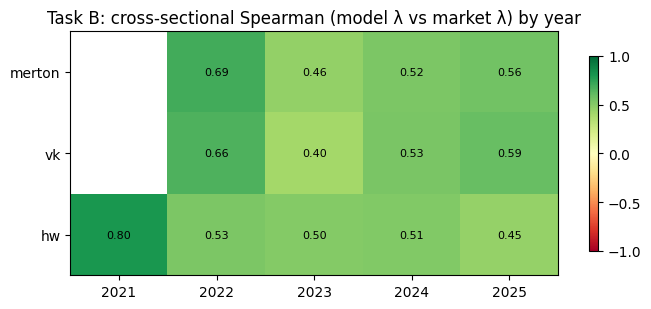

 year  n  Spearman_merton  Kendall_merton  Spearman_vk  Kendall_vk  Spearman_hw  Kendall_hw
 2021  5              NaN             NaN          NaN         NaN     0.800000    0.600000
 2022 73         0.691289        0.510127     0.657781    0.507975     0.525361    0.372146
 2023 78         0.456425        0.341534     0.398993    0.314880     0.501359    0.349983
 2024 79         0.524572        0.397594     0.531627    0.425464     0.513948    0.361895
 2025 79         0.559684        0.425780     0.590319    0.459421     0.452191    0.310613


In [8]:
rows = []
for yr in sorted(panel_v4['year'].unique()):
    sub = panel_v4[panel_v4['year'] == yr]
    row = {'year': yr, 'n': len(sub)}
    for m in ('merton','vk','hw'):
        mcol = f'{m}_lambda'
        s2 = sub[[mcol,'lambda_market']].dropna()
        if len(s2) < 5:
            row[f'Spearman_{m}'] = np.nan
            row[f'Kendall_{m}'] = np.nan
        else:
            row[f'Spearman_{m}'] = float(spearmanr(s2[mcol], s2['lambda_market']).statistic)
            row[f'Kendall_{m}']  = float(kendalltau(s2[mcol], s2['lambda_market']).statistic)
    rows.append(row)
taskB = pd.DataFrame(rows)
taskB.to_csv(os.path.join(OUT_DIR,'taskB_rank_values.csv'), index=False)

# Heatmap
sp = taskB[[c for c in taskB.columns if c.startswith('Spearman_')]]
sp.columns = [c.replace('Spearman_','') for c in sp.columns]
sp.index = taskB['year'].values
fig, ax = plt.subplots(figsize=(7, 3.2))
im = ax.imshow(sp.T.values, aspect='auto', cmap='RdYlGn', vmin=-1, vmax=1)
ax.set_xticks(range(len(sp.index))); ax.set_xticklabels(sp.index)
ax.set_yticks(range(len(sp.columns))); ax.set_yticklabels(sp.columns)
for i in range(sp.shape[1]):
    for j in range(sp.shape[0]):
        v = sp.iloc[j,i]
        if not np.isnan(v):
            ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=8)
ax.set_title('Task B: cross-sectional Spearman (model λ vs market λ) by year')
plt.colorbar(im, ax=ax, shrink=0.8); plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR,'taskB_rank_heatmap.png'), dpi=150, bbox_inches='tight')
plt.show()
print(taskB.to_string(index=False))


## 7. Task C —— 预测实际信用评级

`avrating` 是 S&P/Moody's 的实际评级——独立的 ground truth。
映射到 ordinal score（AAA=1..D=22），然后比较多个候选 score 对 avrating 的 Spearman：

- `merton_neg_DD`（-DD，越大越危险，向评级同向）
- `vk_neg_DD`
- `hw_hazard`
- `markit_dp`（作 peer baseline）
- `markit_impliedrating_ord`（作 peer baseline）

这等于让我们的模型和 Markit 的数据产品**头对头**比较“预测实际评级”的能力。

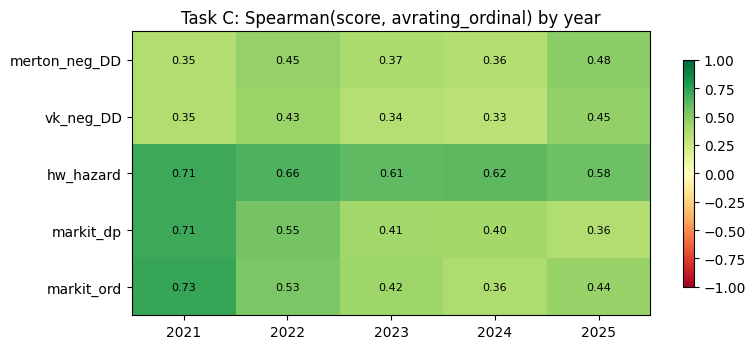

 year  n  merton_neg_DD  vk_neg_DD  hw_hazard  markit_dp  markit_ord
 2021  5       0.353553   0.353553   0.707107   0.707107    0.725476
 2022 73       0.448029   0.432550   0.661719   0.552962    0.527093
 2023 78       0.374706   0.338178   0.612037   0.408925    0.416386
 2024 79       0.358018   0.326960   0.618582   0.402242    0.363051
 2025 79       0.482656   0.454907   0.577069   0.359249    0.437756


In [9]:
RATING_SCALE = {
    'AAA':1,'AA+':2,'AA':3,'AA-':4,'A+':5,'A':6,'A-':7,
    'BBB+':8,'BBB':9,'BBB-':10,'BB+':11,'BB':12,'BB-':13,
    'B+':14,'B':15,'B-':16,'CCC+':17,'CCC':18,'CCC-':19,
    'CC':20,'C':21,'D':22,
}
sub = panel_v4.copy()
sub['avrating_ord']      = sub['avrating'].map(RATING_SCALE)
sub['impliedrating_ord'] = sub['impliedrating'].map(RATING_SCALE)

CANDIDATES = {
    'merton_neg_DD': lambda d: -d['merton_DD'],
    'vk_neg_DD':     lambda d: -d['vk_DD'],
    'hw_hazard':     lambda d:  d['hw_hazard'],
    'markit_dp':     lambda d:  d['dp'],
    'markit_ord':    lambda d:  d['impliedrating_ord'],
}

rows = []
for yr in sorted(sub['year'].unique()):
    s = sub[sub['year']==yr]
    row = {'year':yr,'n':len(s)}
    for name, fn in CANDIDATES.items():
        score = fn(s)
        pair = pd.DataFrame({'score':score,'rating':s['avrating_ord']}).dropna()
        if len(pair) < 5:
            row[name] = np.nan
        else:
            row[name] = float(spearmanr(pair['score'], pair['rating']).statistic)
    rows.append(row)
taskC = pd.DataFrame(rows)
taskC.to_csv(os.path.join(OUT_DIR,'taskC_rating_values.csv'), index=False)

cols = [c for c in taskC.columns if c not in ('year','n')]
M = taskC[cols].T.values
fig, ax = plt.subplots(figsize=(8,3.6))
im = ax.imshow(M, aspect='auto', cmap='RdYlGn', vmin=-1, vmax=1)
ax.set_xticks(range(len(taskC))); ax.set_xticklabels(taskC['year'].values)
ax.set_yticks(range(len(cols))); ax.set_yticklabels(cols)
for i in range(len(cols)):
    for j in range(len(taskC)):
        v = M[i,j]
        if not np.isnan(v):
            ax.text(j,i,f'{v:.2f}',ha='center',va='center',fontsize=8)
ax.set_title('Task C: Spearman(score, avrating_ordinal) by year')
plt.colorbar(im, ax=ax, shrink=0.8); plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR,'taskC_rating_heatmap.png'), dpi=150, bbox_inches='tight')
plt.show()
print(taskC.to_string(index=False))


## 8. 附录 —— V3 Shumway in-sample 评估

> 以下 AUC（0.975 concurrent / 0.994 lagged）是 **within-2023 in-sample 交叉验证**。不是 out-of-time。V3 cell `0ee19e4a` 已经证明经典 walk-forward 因所有正例都在 2023而失败。这里仅作为“V3 说了什么”的存档，**主评估是 Sections 5–7**。

In [10]:
m_a = pd.read_csv('hull_white_package/outputs/v3_shumway/metrics_v3.csv')
m_b = pd.read_csv('hull_white_package/outputs/v3_shumway/metrics_lagged_v3.csv')
print('Stage A (concurrent features):')
print(m_a.to_string(index=False))
print()
print('Stage B2 (lagged features):')
print(m_b.to_string(index=False))


Stage A (concurrent features):
              metric      value
          pooled_AUC   0.975376
           pooled_AR   0.950751
       fold_mean_AUC   0.975783
        fold_std_AUC   0.009594
        fold_mean_AR   0.951566
         fold_std_AR   0.019187
 bootstrap_n_success 200.000000
  bootstrap_n_failed   0.000000
bootstrap_AUC_median   0.977478
 bootstrap_AUC_ci_lo   0.966318
 bootstrap_AUC_ci_hi   0.987902
         n_rows_kept 619.000000
        n_firms_kept 162.000000
          n_positive  20.000000
          n_negative 599.000000

Stage B2 (lagged features):
                     metric      value
          pooled_AUC_lagged   0.993593
           pooled_AR_lagged   0.987185
       fold_mean_AUC_lagged   0.994324
        fold_std_AUC_lagged   0.005294
        fold_mean_AR_lagged   0.988648
         fold_std_AR_lagged   0.010589
 bootstrap_n_success_lagged 200.000000
  bootstrap_n_failed_lagged   0.000000
bootstrap_n_fallback_lagged   0.000000
bootstrap_AUC_median_lagged   0.993959

## 9. 最终对比表

单张表汇总所有评估口径。

In [11]:
def ga(m, target, col):
    v = taskA.loc[(taskA['model']==m) & (taskA['target']==target), col]
    return float(v.values[0]) if len(v) else np.nan
def gb(m): return float(taskB[f'Spearman_{m}'].mean())
def gc(m):
    col = f'{m}_neg_DD' if m in ('merton','vk') else f'{m}_hazard'
    return float(taskC[col].mean()) if col in taskC.columns else np.nan

pA_auc = float(m_a.loc[m_a['metric']=='pooled_AUC','value'].values[0])
pB_auc = float(m_b.loc[m_b['metric']=='pooled_AUC_lagged','value'].values[0])

final = pd.DataFrame([
    {'model':m,
     'TaskA_R2_lambda': ga(m,'lambda','R2'),
     'TaskA_RMSE_lambda': ga(m,'lambda','RMSE'),
     'TaskA_Spearman_lambda': ga(m,'lambda','Spearman'),
     'TaskA_R2_PD5y': ga(m,'PD_5y','R2'),
     'TaskB_mean_Spearman': gb(m),
     'TaskC_mean_Spearman_vs_avrating': gc(m),
     'V3_Stage_A_AUC_inSample':  pA_auc if m=='hw' else np.nan,
     'V3_Stage_B2_AUC_inSample': pB_auc if m=='hw' else np.nan}
    for m in ('merton','vk','hw')
])
final.to_csv(os.path.join(OUT_DIR,'final_comparison.csv'), index=False)
print(final.to_string(index=False))


 model  TaskA_R2_lambda  TaskA_RMSE_lambda  TaskA_Spearman_lambda  TaskA_R2_PD5y  TaskB_mean_Spearman  TaskC_mean_Spearman_vs_avrating  V3_Stage_A_AUC_inSample  V3_Stage_B2_AUC_inSample
merton        -2.041892           0.011707               0.566592      -2.377127             0.557993                         0.403392                      NaN                       NaN
    vk        -2.065991           0.011753               0.556298      -2.405331             0.544680                         0.381230                      NaN                       NaN
    hw      -194.557627           0.093864               0.526157     -71.008166             0.558572                         0.635303                 0.975376                  0.993593


## 10. 讨论与 limitations

**观察到什么：**

- **Task A raw R² 深度为负**：Merton/VK 对 IG 公司 PD 预测接近 0，而 Markit dp 在 1–3% 量级，level 系统性低估。这是结构化模型的已知特征（IG 公司 DD 太大）。
- **Task A calibrated R² 明显改善**：加一个线性 `a + b × λ_model` 校准后，OOT calib_R² 从 -3~-4 升到 -0.5 左右。b≈0.4–0.5 说明市场 λ 是模型 λ 的 ~2.5 倍。
- **Task B 横截面 rank 很强**：Merton/VK 平均 Spearman 0.55 左右，HW 同量级。模型无法告诉你“违约概率的绝对水平”，但能相当准确地告诉你“哪家更危险”。
- **Task C 中 HW 出人意料地强**（mean Spearman 0.63），超越 Markit impliedrating（0.48），也超越我们自己的 Merton_neg_DD（0.40）。这说明 logistic hazard（即使是从 163 firms 迁移的系数）对 IG 公司实际评级的判别能力比纯结构模型 DD 还强。

**核心 limitations：**

1. 样本全为投资级：84 家公司都在 A/AA/BBB 区间，tail risk（HY、default）未被验证。
2. `dp` 和 `parspread` 数学等价（都是 CDS spread 的函数），所以对 dp 的预测和对 spread 的预测是同一件事。
3. HW 在 V4 是 V3 系数的迁移，不是在 IG 数据上重训（IG 上无正例无法训）。
4. 2021 年 cached panel 覆盖不全（仅 5 行），实质评估从 2022 开始。
5. V3 in-sample AUC 0.975/0.994 **不是** time-out-of-sample 数字，报告时必须显式说明。